# Detector de voz sintética em inglês: v3 (padding de áudio curto)

> **Um detector que classifica se uma voz em inglês foi gerada por IA, para alertar contra golpes de clonagem de voz e evitar que ouvintes e sistemas confiem em um áudio que finge ser uma pessoa real.**

**Objetivo desta versão:** testar **o efeito do padding** de áudios curtos. Até a v2, todo áudio com menos de 4 s era **repetido** até completar 4 s. Aqui comparamos isso com **completar com silêncio (zeros)**, mudando só essa regra, com **3 seeds por condição** e comparação **pareada por seed**. Não é a correção de um problema comprovado: é um teste, pré-registrado antes dos resultados.

Este notebook contém **só a versão atual (v3)**. As anteriores estão arquivadas em [`notebooks/versions/`](notebooks/versions/) e o registro de todas as versões (com o pré-registro da v3) fica em [`docs/HISTORICO_VERSOES.md`](docs/HISTORICO_VERSOES.md).

## Histórico das versões

**O que faz:** lê `results/baseline_results.csv` (v1) e `results/experiments.csv` (v2 em diante) e mostra uma linha por versão/experimento.
**Por quê:** antes de propor algo novo, todo mundo vê o que já foi tentado.

Como ler: "val (média por fonte)" e "dev_shift" são os números usados para **decidir**; as colunas de teste são só para **reportar** (cada versão é avaliada no teste uma única vez). As linhas da v3 trazem validação e dev_shift; o teste final da v3 ainda **não** foi avaliado (etapa separada), por isso as colunas de teste dela ficam vazias.

| versão | o que mudou | resultado em uma frase |
|:--|:--|:--|
| v1 | baseline: CNN pequena em log-mel, sem augmentation | ótimo na validação (EER 1,3%) e péssimo fora: In-the-Wild com AUC 0,211 |
| v2 · v1r | só a regra do checkpoint (EER média por fonte) | parecido com a v1; dev_shift AUC 0,325 |
| v2 · v2a | + volume (RMS e ganho), um controle | dev_shift 0,386: tomado como o tamanho do acaso entre execuções |
| v2 · v2b | + ruído, banda de telefone e mu-law | robusto às degradações que viu, sem ganho no dev_shift além do controle; "limpo = real" **não se confirmou** |
| v3 | padding de áudio curto: repetir × zeros, 3 seeds cada | **sem efeito demonstrado** no dev_shift (Δ EER pareado −3,1 / +20,1 / −12,8 pontos, sinais trocados); as seis execuções com AUC abaixo de 0,5; o acaso entre seeds chega a 0,23 de AUC |

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display


def _pct(v):
    return "—" if pd.isna(v) else f"{100 * v:.1f}%"


def _auc(v):
    return "—" if pd.isna(v) else f"{v:.3f}"


hist_linhas = []
b = pd.read_csv("results/baseline_results.csv", index_col=0)
hist_linhas.append({
    "versão": "v1 (baseline)", "teste avaliado com": "recorte central",
    "EER val (global)": _pct(b.loc["validação", "EER"]),
    # média das EER por fonte da validação, da seção 7.3 do notebook v1: (0,26% + 7,82% + 32,69%) / 3
    "EER val (média por fonte)": _pct((0.002641 + 0.078220 + 0.326868) / 3),
    "dev_shift AUC": "—", "dev_shift EER": "—",
    "In-the-Wild AUC": _auc(b.loc["in_the_wild", "AUC"]) + " (banco inteiro)",
    "CORAA falso alarme": _pct(b.loc["coraa", "falso alarme"]),
    "notebook": "notebooks/versions/v1_baseline.ipynb"})

e = pd.read_csv("results/experiments.csv")
for exp, g in e.groupby("experimento", sort=False):
    def pega(conjunto, banco, col, modo):
        s = g[(g.conjunto == conjunto) & (g.banco == banco) & (g["avaliação"] == modo)][col]
        return s.iloc[0] if len(s) else float("nan")
    versao = g["versão"].iloc[0]
    hist_linhas.append({
        "versão": f"{versao} · {exp}", "teste avaliado com": "janelas de 4 s (passo 2 s)",
        "EER val (global)": _pct(pega("validação", "todas as fontes", "EER", "central")),
        "EER val (média por fonte)": _pct(g["EER média por fonte val (checkpoint)"].iloc[0]),
        "dev_shift AUC": _auc(pega("dev_shift", "in_the_wild", "AUC", "janelas")),
        "dev_shift EER": _pct(pega("dev_shift", "in_the_wild", "EER", "janelas")),
        "In-the-Wild AUC": _auc(pega("test_final", "in_the_wild", "AUC", "janelas")) + " (test_final)",
        "CORAA falso alarme": _pct(pega("test_final", "coraa", "falso alarme", "janelas")),
        "notebook": "notebooks/versions/" + {"v2": "v2_augmentation.ipynb", "v3": "v3_padding.ipynb"}.get(versao, "?")})
if not (e["versão"] == "v3").any():
    print("v3: ainda sem linhas em results/experiments.csv (os seis treinos estão pendentes).")
display(Markdown(pd.DataFrame(hist_linhas).to_markdown(index=False)))

| versão               | teste avaliado com         | EER val (global)   | EER val (média por fonte)   | dev_shift AUC   | dev_shift EER   | In-the-Wild AUC       | CORAA falso alarme   | notebook                                 |
|:---------------------|:---------------------------|:-------------------|:----------------------------|:----------------|:----------------|:----------------------|:---------------------|:-----------------------------------------|
| v1 (baseline)        | recorte central            | 1.3%               | 13.6%                       | —               | —               | 0.211 (banco inteiro) | 41.6%                | notebooks/versions/v1_baseline.ipynb     |
| v2 · v1r             | janelas de 4 s (passo 2 s) | 1.4%               | 12.6%                       | 0.325           | 63.7%           | 0.262 (test_final)    | 34.9%                | notebooks/versions/v2_augmentation.ipynb |
| v2 · v2a             | janelas de 4 s (passo 2 s) | 1.1%               | 13.0%                       | 0.386           | 58.1%           | 0.354 (test_final)    | 24.3%                | notebooks/versions/v2_augmentation.ipynb |
| v2 · v2b             | janelas de 4 s (passo 2 s) | 2.0%               | 14.3%                       | 0.389           | 57.0%           | 0.336 (test_final)    | 29.8%                | notebooks/versions/v2_augmentation.ipynb |
| v3 · v3_repeat_s42   | janelas de 4 s (passo 2 s) | 2.2%               | 14.1%                       | 0.241           | 69.6%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |
| v3 · v3_zero_s42     | janelas de 4 s (passo 2 s) | 2.8%               | 13.7%                       | 0.274           | 66.5%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |
| v3 · v3_repeat_s123  | janelas de 4 s (passo 2 s) | 2.6%               | 13.2%                       | 0.378           | 59.2%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |
| v3 · v3_zero_s123    | janelas de 4 s (passo 2 s) | 1.2%               | 11.2%                       | 0.146           | 79.4%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |
| v3 · v3_repeat_s2026 | janelas de 4 s (passo 2 s) | 1.6%               | 12.6%                       | 0.228           | 70.5%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |
| v3 · v3_zero_s2026   | janelas de 4 s (passo 2 s) | 1.6%               | 12.3%                       | 0.377           | 57.7%           | — (test_final)        | —                    | notebooks/versions/v3_padding.ipynb      |

## 1. Introdução

### 1.1 O que a v2 deixou

A v2 terminou sem resolver o In-the-Wild (dev_shift com AUC abaixo de 0,5) e **sem confirmar** a hipótese "gravação limpa = real" (não a usamos como premissa aqui). Entre as pistas que ela anotou, uma é sobre **duração**: a inversão parecia pior nos áudios curtos, e 68% dos reais do In-the-Wild têm menos de 4 s, ou seja, são **repetidos** até 4 s antes de entrar na CNN.

### 1.2 A premissa foi medida? (Etapa 0)

Antes de implementar, medimos de novo, com as notas salvas da v2 (**só validação e dev_shift**), o desempenho por **duração original** do arquivo (seção 5.1 mostra a tabela completa):
- **No dev_shift, sim:** AUC do v1r 0,24 (< 2 s), 0,30 (2 a < 4 s) e 0,43 (≥ 4 s); o mesmo padrão no v2a e no v2b, e também **dentro do locutor** (13 locutores com as três faixas).
- **Na validação, não:** AUC ≈ 0,99 nas três faixas.
- **O que isso não mostra:** que a **repetição** é a causa. É uma associação: os curtos do dev_shift têm mais reais (85%), outros locutores e outras gravações. A v2 nunca testou uma alternativa à repetição.
- Não encontramos nos arquivos salvos o achado "CORAA com mais de 6 s com 60% a 70% de falso alarme", e não o recalculamos (o CORAA é teste).

### 1.3 A hipótese e a alternativa

**Hipótese (a testar):** repetir áudios curtos até 4 s pode introduzir padrões artificiais (a "costura" entre as cópias, ritmo periódico) que prejudicam a generalização; completar com silêncio, mantendo o resto, pode reduzir isso.

**Alternativa, igualmente plausível:** os zeros **também** são artificiais. No log-mel, silêncio digital vira uma faixa de energia mínima, cuja **largura conta a duração** do áudio, e essa faixa entra na padronização (média e desvio) de cada exemplo. No treino, a duração difere entre real e fake dentro das fontes (seção 5.2), então o modelo pode aprender "quanto silêncio tem" como pista. **Não assumimos que o zero-padding é melhor.**

### 1.4 Desenho do experimento (pré-registrado)

| execução | áudio < 4 s | seed de treino | o resto |
|:--|:--|:--|:--|
| `v3_repeat_s42`, `v3_repeat_s123`, `v3_repeat_s2026` | repetido até 4 s (o de sempre) | 42, 123, 2026 | igual ao v1r da v2: CNN pequena, log-mel 64, 16 kHz, 4 s, **sem augmentation**, mesma amostragem, mesmos splits e hiperparâmetros, checkpoint pela EER média por fonte, avaliação por janelas |
| `v3_zero_s42`, `v3_zero_s123`, `v3_zero_s2026` | fala original + zeros à direita até 4 s | 42, 123, 2026 | idem |

- Áudios com 4 s ou mais são tratados **igual** nas duas condições.
- Ordem de execução intercalada por seed: repeat/42, zero/42, repeat/123, zero/123, repeat/2026, zero/2026.
- **Comparação principal:** Δ = EER(zero) − EER(repeat) no dev_shift, **por seed**. Só chamamos de efeito se os três Δ tiverem o mesmo sinal **e** a média dos Δ for maior que a variação entre as seeds do `v3_repeat`. Critérios completos: [`docs/HISTORICO_VERSOES.md`](docs/HISTORICO_VERSOES.md), seção "v3 - pré-registro" (escrita antes de qualquer resultado).
- Os resultados antigos (v1r, v2a, v2b) são contexto: **não** substituem os controles pareados, que usam o mesmo código da v3.

### 1.5 Regras do jogo

- Bancos de teste nunca entram no treino nem na escolha de configuração ou seed.
- Decisões usam **validação + dev_shift**. O dev_shift é para desenvolvimento, nunca para treino.
- O **teste final** fica atrás da flag `AVALIAR_TESTE_FINAL = False`: é uma etapa separada, feita **uma vez**, depois dos seis treinos e da análise de validação/dev_shift, e reporta **todas** as condições e seeds.
- **Ressalva sobre o In-the-Wild:** ele foi consultado inteiro na v1, antes de existirem dev_shift e test_final. A separação melhora o procedimento daqui em diante, mas o test_final do In-the-Wild **não** é uma avaliação historicamente nunca vista.
- Nunca invertemos a nota do modelo com base no teste.

### 1.6 Fora da trilha

> ⚠️ **Fora da trilha:** explicação curta do que é e por que foi usado.

| item novo nesta versão | onde | por que precisamos |
|:--|:--|:--|
| Padding da **onda** com zeros (não é o padding de convolução da trilha) | seções 2, 4 | é a mudança testada |
| Várias seeds e comparação **pareada** por seed | seções 2, 7.4 | separar o efeito da mudança do acaso do treino |
| Pré-registro dos critérios antes dos resultados | `docs/HISTORICO_VERSOES.md` | evitar escolher o critério depois de ver o número |
| Treino retomável e gravação atômica | `scripts/treinar_experimento.py`, `src/arquivos.py` | um treino que cai não corrompe resultados e continua de onde parou |

Os itens fora da trilha das versões anteriores (log-mel, BatchNorm, `BCEWithLogitsLoss`, amostragem balanceada, ROC/AUC/EER, dev_shift, EER média por fonte, janelas deslizantes) continuam valendo e estão explicados nos notebooks v1 e v2.

## 2. Configuração

**O que faz:** importa as bibliotecas e o código de `src/`, define **todos os hiperparâmetros numa célula só** (com as condições e as seeds da v3), fixa a seed dos dados e detecta a GPU.
**Por quê:** com tudo num lugar, o notebook e o script de treino usam exatamente os mesmos valores. `scripts/treinar_experimento.py` executa **esta célula** (tag `config`) para treinar cada execução num processo separado; a condição e a seed chegam ao script como argumentos (`--condicao`, `--seed`), sem editar texto do notebook.

**Flags:**
- **`QUICK`:** `True` roda com poucas centenas de áudios e 2 épocas, para testar de ponta a ponta em minutos; os arquivos levam o sufixo `_quick` e **não valem como resultado**. O script força o valor com `--quick` (variável `QUICK_DO_SCRIPT`), sem trocar texto.
- **`REUSAR`:** `True` lê do disco as notas do teste final já calculadas, para que ele seja calculado **uma vez só** por execução.
- **`AVALIAR_TESTE_FINAL`:** `False`. Com `False` (e sempre no QUICK), o notebook **não consulta nem executa** nada do teste final. Só muda para `True` numa etapa separada, depois dos seis treinos e da análise de validação/dev_shift.

**Os treinos não rodam aqui.** No Windows, o limite de memória reservada já derrubou treinos (ver `docs/HISTORICO_VERSOES.md`, seção h). Cada execução roda num processo próprio, pelo `scripts/rodar_v3.ps1`; este notebook só **lê** o que elas gravaram.

**Hiperparâmetros herdados (sem mudança; justificativas completas no notebook v1, seção 2):**

| hiperparâmetro | valor | por quê (uma frase) |
|:--|:--|:--|
| `SEED` (dados) | 42 | fixa as amostras de validação/dev_shift/teste, iguais para todas as execuções |
| `SAMPLE_RATE`, mono | 16 kHz, 1 canal | taxa da maioria dos bancos; taxa única elimina o atalho da taxa de amostragem |
| `CROP_S` | 4 s | cobre a mediana de duração da maioria dos bancos; entrada de tamanho fixo |
| `N_MELS`, `N_FFT`, `WIN_LENGTH`, `HOP_LENGTH` | 64, 512, 400, 160 | padrão de fala; entrada pequena (64 × 401) |
| `BATCH_SIZE`, `LR` | 64, 0,001 | mini-batch e taxa do Adam recomendados na Aula 6 |
| `DROPOUT` | 0,3 | regularização moderada da Aula 7 |
| `MAX_EPOCHS`, `PATIENCE` | 30, 5 | teto de tempo e early stopping da Aula 7 |
| `PER_CLASS_PER_EPOCH` | 25.000 | 50 mil áudios por época, cobrindo quase todo o pool em 15 a 30 épocas |
| `VAL_MAX`, `DEV_SHIFT_MAX_PER_CLASS` | todos | os dois conjuntos decidem, então usamos eles inteiros |
| `TEST_MAX_PER_CLASS` | 5.000 | limita o tempo do teste final (só na etapa final) |
| `JANELA_S`, `PASSO_S` | 4 s, 2 s | janela do tamanho do treino; passo de meia janela cobre todo trecho |
| `NUM_WORKERS` | 4 | memória no Windows (~1 GB por worker); o script aceita `--num-workers` |

**Novos nesta versão:**

| hiperparâmetro | valor | por quê (uma frase) |
|:--|:--|:--|
| `CONDICOES` (`short_audio_mode`) | `"repeat"`, `"zero"` | a única mudança testada: repetir o áudio curto ou completar com zeros à direita |
| `SEEDS_TREINO` | 42, 123, 2026 | três execuções por condição para medir o acaso do treino |
| `RECORTE_DETERMINISTICO` | `True` | a posição do recorte aleatório depende só de (seed, época, áudio), então as duas condições recebem os mesmos trechos e o resultado não depende do número de workers |

> ⚠️ **Fora da trilha (fontes de aleatoriedade separadas):** a seed de treino alimenta três sorteadores independentes: a **amostragem das épocas** (`src/sampling.py`), o **recorte aleatório** (`src/dataset.py`) e a **inicialização da CNN** (`torch.manual_seed` logo antes de criá-la; o dropout usa o mesmo gerador global). Como nenhum deles depende da condição, na mesma seed `repeat` e `zero` veem os mesmos áudios, na mesma ordem, com os mesmos trechos; só muda o que acontece com os curtos. Isso **não** garante resultados idênticos bit a bit na GPU (operações da cuDNN podem variar), e isso não foi verificado.

In [2]:
import json
import math
import random
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from IPython.display import Audio, Markdown, display
from sklearn.metrics import roc_auc_score

from src.analysis import FAIXAS_DURACAO, faixa_duracao, metricas_por_duracao
from src.dataset import (MODOS_CURTO, AudioDataset, AudioInteiroDataset, completar_curto,
                         limitar_threads_dos_workers)
from src.experimento import (amostra_dev_shift, amostra_teste, calcular_notas, carregar_modelo, ler_manifest,
                             preparar_treino)
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas, sigmoide
from src.model import LogMelPadronizado

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta | False: tudo completo
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK)   # scripts/treinar_experimento.py --quick força True aqui
REUSAR = True                # True: lê do disco as notas do teste final já calculadas (uma vez por execução)
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado (só depois dos 6 treinos e da análise)

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras de validação, dev_shift e teste); não muda entre execuções
SAMPLE_RATE = 16_000
CROP_S = 4.0
N_MELS, N_FFT, WIN_LENGTH, HOP_LENGTH = 64, 512, 400, 160
BATCH_SIZE = 64
LR = 1e-3
DROPOUT = 0.3
MAX_EPOCHS = 30
PATIENCE = 5
PER_CLASS_PER_EPOCH = 25_000
VAL_MAX = None
TEST_MAX_PER_CLASS = 5_000
NUM_WORKERS = 4
DEV_SHIFT_MAX_PER_CLASS = None   # None = dev_shift inteiro
JANELA_S, PASSO_S = 4.0, 2.0     # avaliação por janelas deslizantes
AUDIOS_POR_LOTE_JANELAS = 16

# ---------------- novos nesta versão ----------------
CONDICOES = ("repeat", "zero")   # short_audio_mode: repetir o áudio curto | completar com zeros à direita
SEEDS_TREINO = (42, 123, 2026)
RECORTE_DETERMINISTICO = True    # posição do recorte = f(seed, época, áudio), independente da condição e dos workers

if QUICK:
    PER_CLASS_PER_EPOCH, MAX_EPOCHS, PATIENCE = 150, 2, 2
    VAL_MAX, TEST_MAX_PER_CLASS, DEV_SHIFT_MAX_PER_CLASS = 300, 50, 50

DESCRICAO = {"repeat": "áudio < 4 s repetido até 4 s (como v1r); sem augmentation",
             "zero": "áudio < 4 s: fala original + zeros à direita até 4 s; sem augmentation"}
# ordem intercalada por seed: repeat/42, zero/42, repeat/123, zero/123, repeat/2026, zero/2026
EXPERIMENTOS = {f"v3_{c}_s{s}": dict(descricao=DESCRICAO[c], aug={}, short_audio_mode=c, seed=s)
                for s in SEEDS_TREINO for c in CONDICOES}
VERSAO = "v3"
# o que o treino e as notas precisam (src/experimento.py e scripts/treinar_experimento.py)
HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, CROP_S=CROP_S, N_MELS=N_MELS, N_FFT=N_FFT,
          WIN_LENGTH=WIN_LENGTH, HOP_LENGTH=HOP_LENGTH, BATCH_SIZE=BATCH_SIZE, LR=LR, DROPOUT=DROPOUT,
          MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, PER_CLASS_PER_EPOCH=PER_CLASS_PER_EPOCH,
          VAL_MAX=VAL_MAX, TEST_MAX_PER_CLASS=TEST_MAX_PER_CLASS, NUM_WORKERS=NUM_WORKERS,
          DEV_SHIFT_MAX_PER_CLASS=DEV_SHIFT_MAX_PER_CLASS, JANELA_S=JANELA_S, PASSO_S=PASSO_S,
          AUDIOS_POR_LOTE_JANELAS=AUDIOS_POR_LOTE_JANELAS, RECORTE_DETERMINISTICO=RECORTE_DETERMINISTICO,
          AUG_BASE={})

# ---------------- memória: workers com 1 thread de álgebra linear (não muda nenhum resultado) ----------------
limitar_threads_dos_workers()

# ---------------- reprodutibilidade, dispositivo e arquivos ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELS_DIR, RESULTS_DIR = Path("models"), Path("results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
SUFFIX = "_quick" if QUICK else ""
EXPERIMENTS_CSV = RESULTS_DIR / f"experiments{SUFFIX}.csv"


def caminho_ckpt(exp):
    return MODELS_DIR / f"{exp}_cnn{SUFFIX}.pt"


def caminho_estado(exp):          # só existe enquanto um treino está incompleto (para retomar)
    return MODELS_DIR / f"{exp}_estado{SUFFIX}.pt"


def caminho_hist(exp):
    return RESULTS_DIR / f"{exp}_historico{SUFFIX}.csv"


def caminho_notas(exp, conjunto):
    return RESULTS_DIR / f"{exp}_notas_{conjunto}{SUFFIX}.parquet"


def caminho_marcador(exp):        # gravado por último: só com ele a execução conta como concluída
    return RESULTS_DIR / f"{exp}_concluido{SUFFIX}.json"


print(f"QUICK = {QUICK} | REUSAR = {REUSAR} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL}")
print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | dispositivo: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print("execuções:", ", ".join(EXPERIMENTOS))

QUICK = False | REUSAR = True | AVALIAR_TESTE_FINAL = False
torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | dispositivo: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
execuções: v3_repeat_s42, v3_zero_s42, v3_repeat_s123, v3_zero_s123, v3_repeat_s2026, v3_zero_s2026


**O que faz:** define o estilo dos gráficos (cores fixas por condição) e duas funções de formatação.
**Por quê:** as mesmas cores em todas as figuras: azul = real, laranja = fake; roxo = `repeat`, verde = `zero`.

In [3]:
REAL_C, FAKE_C = "#2a78d6", "#eb6834"          # azul = real, laranja = fake (sempre)
COR_COND = {"repeat": "#6250d6", "zero": "#1baf7a"}
MARCA_SEED = {42: "o", 123: "s", 2026: "^"}
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 9})


def fmt(n):
    # Número inteiro com ponto de milhar (padrão brasileiro).
    return f"{int(n):,}".replace(",", ".")


def show_md(df, **kw):
    display(Markdown(df.to_markdown(**kw)))

## 3. Mapa do banco (resumo)

O banco **não mudou** desde a v2 (mesmo manifest, mesmos splits, mesmo dev_shift). A descrição completa está em:
- [`docs/dataset_overview.md`](docs/dataset_overview.md): tabelas por fonte, contagens, exclusões e decisões;
- [`docs/audit_report.md`](docs/audit_report.md): auditoria dos dados e o dev_shift (seção 7);
- [`notebooks/versions/v1_baseline.ipynb`](notebooks/versions/v1_baseline.ipynb) (seções 3 a 5) e [`notebooks/versions/v2_augmentation.ipynb`](notebooks/versions/v2_augmentation.ipynb) (seção 3.2, dev_shift).

### 3.1 O manifest e o dev_shift

**O que faz:** carrega o manifest, mostra o funil por split e monta a amostra do dev_shift usada na avaliação.
**Por quê:** o manifest é a única fonte da verdade sobre os dados; o dev_shift é o conjunto fora do domínio que pode decidir entre versões.

In [4]:
df = ler_manifest()        # excluídos com split = "excluded" (só em memória) e label como int
funil = df.groupby("split")["label"].agg(áudios="size", real=lambda s: int((s == 0).sum()),
                                         fake=lambda s: int((s == 1).sum())).reindex(["train", "val", "test", "excluded"])
funil["% do total"] = (100 * funil["áudios"] / len(df)).round(1)
display(funil)
dev_df = amostra_dev_shift(df, HP)                              # src/experimento.py (seed dos dados)
print(f"dev_shift usado: {fmt(len(dev_df))} áudios ({fmt((dev_df.label == 0).sum())} reais, "
      f"{fmt((dev_df.label == 1).sum())} fakes, {dev_df.speaker_id.nunique()} locutores)")

,áudios,real,fake,% do total
split,,,,
train,260782,69122,191660,34.5
val,51189,15730,35459,6.8
test,416844,57096,359748,55.1
excluded,27535,11749,15786,3.6


dev_shift usado: 10.614 áudios (8.633 reais, 1.981 fakes, 16 locutores)


### 3.2 Duração original por conjunto e classe (novo)

**O que faz:** conta quantos áudios de treino, validação e dev_shift caem em cada faixa de **duração original** (a do arquivo, antes de repetir ou completar): < 2 s, 2 a < 4 s e ≥ 4 s.
**Por quê:** só os áudios com menos de 4 s mudam entre `repeat` e `zero`. Esta tabela diz **quanto** de cada conjunto a mudança atinge. Os bancos de teste não entram aqui.

In [5]:
d = df[df.split.isin(["train", "val"]) | (df.eval_subset == "dev_shift")].copy()
d["conjunto"] = np.where(d.eval_subset == "dev_shift", "dev_shift", d.split)
d["classe"] = d.label.map({0: "real", 1: "fake"})
d["faixa"] = faixa_duracao(d.duration_s)
TAB_DUR = pd.crosstab([d.conjunto, d.classe], d.faixa)
TAB_DUR_PCT = pd.crosstab([d.conjunto, d.classe], d.faixa, normalize="index").mul(100).round(1)
TAB_DUR = TAB_DUR.reindex(["train", "val", "dev_shift"], level=0)
show_md(TAB_DUR.astype(str) + " (" + TAB_DUR_PCT.reindex(TAB_DUR.index).astype(str) + "%)")
curtos = (d.duration_s < CROP_S).groupby(d.conjunto).mean().mul(100).round(1)
print("áudios com menos de 4 s (afetados pela mudança):", curtos.to_dict(), "(%)")

|                       | < 2 s        | 2 a < 4 s      | ≥ 4 s         |
|:----------------------|:-------------|:---------------|:--------------|
| ('train', 'fake')     | 8739 (4.6%)  | 101063 (52.7%) | 81858 (42.7%) |
| ('train', 'real')     | 1947 (2.8%)  | 32972 (47.7%)  | 34203 (49.5%) |
| ('val', 'fake')       | 616 (1.7%)   | 18111 (51.1%)  | 16732 (47.2%) |
| ('val', 'real')       | 270 (1.7%)   | 7189 (45.7%)   | 8271 (52.6%)  |
| ('dev_shift', 'fake') | 353 (17.8%)  | 759 (38.3%)    | 869 (43.9%)   |
| ('dev_shift', 'real') | 2067 (23.9%) | 3772 (43.7%)   | 2794 (32.4%)  |

áudios com menos de 4 s (afetados pela mudança): {'dev_shift': 65.5, 'train': 55.5, 'val': 51.2} (%)


**Conclusão:** mais da metade dos áudios de treino e de validação tem menos de 4 s (a maior parte entre 2 e 4 s), e no dev_shift são cerca de dois terços. Então a mudança atinge a maior parte do que o modelo vê, e não só um canto dos dados. No dev_shift, os reais são mais curtos que os fakes. Na validação e no treino, a diferença de duração entre as classes depende da fonte (seção 5.2).

## 4. Visualização: o que a CNN recebe em cada condição

**O que faz:** pega um áudio real curto (< 2 s) da validação e mostra a onda e o log-mel **padronizado** (exatamente o que a CNN recebe) com `repeat` e com `zero`, na mesma escala de cor. Depois mede, nas duas versões, o valor do log-mel na parte completada e a média e o desvio usados na padronização.
**Por quê:** para ver a diferença real entre as condições antes de treinar. Os zeros não são "nada": viram uma região de energia mínima no log-mel, e essa região entra na média e no desvio da padronização.

exemplo: dfadd, real, 1.99 s -> 31821 amostras de fala, 32179 completadas (50% da entrada)


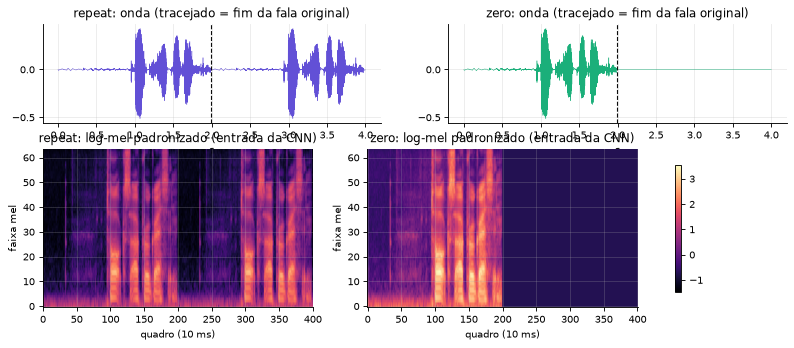

| condição   |   amostras | fala original preservada   |   média do log-mel bruto |   desvio do log-mel bruto |   log-mel padronizado na parte da fala (média) |   log-mel padronizado na parte completada (média) |
|:-----------|-----------:|:---------------------------|-------------------------:|--------------------------:|-----------------------------------------------:|--------------------------------------------------:|
| repeat     |      64000 | True                       |                    -6.88 |                      4.74 |                                          -0    |                                             -0    |
| zero       |      64000 | True                       |                   -10.35 |                      4.82 |                                           0.72 |                                             -0.72 |

**repeat**

**zero**

In [6]:
ex = df[(df.split == "val") & (df.label == 0) & (df.duration_s < 2.0)].sample(1, random_state=SEED).iloc[0]
logmel_cpu = LogMelPadronizado(SAMPLE_RATE, N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS)
N_OUT = int(CROP_S * SAMPLE_RATE)
ondas, imagens = {}, {}
for modo in CONDICOES:
    ondas[modo] = AudioDataset([ex.path], [0], [ex.sample_rate], [ex.duration_s], crop_s=CROP_S,
                               target_sr=SAMPLE_RATE, mode="center", short_audio_mode=modo)[0][0]
    imagens[modo] = logmel_cpu(ondas[modo][None])[0, 0]
n_fala = int(round(ex.duration_s * SAMPLE_RATE))
q_fala = n_fala // HOP_LENGTH                   # primeiro quadro do log-mel que já é só complemento (aprox.)
print(f"exemplo: {ex.source_dataset}, real, {ex.duration_s:.2f} s -> {n_fala} amostras de fala, "
      f"{N_OUT - n_fala} completadas ({100 * (N_OUT - n_fala) / N_OUT:.0f}% da entrada)")

fig, axes = plt.subplots(2, 2, figsize=(12, 4.6), gridspec_kw={"height_ratios": [1, 1.6]})
vmin = min(float(m.min()) for m in imagens.values())
vmax = max(float(m.max()) for m in imagens.values())
t = np.arange(N_OUT) / SAMPLE_RATE
for j, modo in enumerate(CONDICOES):
    axes[0, j].plot(t, ondas[modo].numpy(), lw=0.4, color=COR_COND[modo])
    axes[0, j].axvline(n_fala / SAMPLE_RATE, color="#0b0b0b", ls="--", lw=1)
    axes[0, j].set_title(f"{modo}: onda (tracejado = fim da fala original)")
    axes[0, j].set_xlabel("s")
    im = axes[1, j].imshow(imagens[modo].numpy(), origin="lower", aspect="auto", vmin=vmin, vmax=vmax, cmap="magma")
    axes[1, j].set_title(f"{modo}: log-mel padronizado (entrada da CNN)")
    axes[1, j].set_xlabel("quadro (10 ms)")
    axes[1, j].set_ylabel("faixa mel")
fig.colorbar(im, ax=axes[1, :], shrink=0.8)
plt.show()

linhas = []
for modo in CONDICOES:
    m = imagens[modo]
    bruto = torch.log(logmel_cpu.mel(ondas[modo][None]) + 1e-6)[0]
    linhas.append({"condição": modo, "amostras": ondas[modo].numel(),
                   "fala original preservada": bool(torch.equal(ondas[modo][:n_fala], ondas["repeat"][:n_fala])),
                   "média do log-mel bruto": round(float(bruto.mean()), 2),
                   "desvio do log-mel bruto": round(float(bruto.std()), 2),
                   "log-mel padronizado na parte da fala (média)": round(float(m[:, : q_fala - 2].mean()), 2),
                   "log-mel padronizado na parte completada (média)": round(float(m[:, q_fala + 2:].mean()), 2)})
show_md(pd.DataFrame(linhas), index=False)
for modo in CONDICOES:
    display(Markdown(f"**{modo}**"), Audio(ondas[modo].numpy(), rate=SAMPLE_RATE))

**Conclusão:** nas duas condições a entrada tem 64.000 amostras e a fala original fica intacta no começo. Com `repeat`, a parte completada é a mesma fala de novo, e o log-mel padronizado parece "fala contínua". Com `zero`, a parte completada vira uma faixa uniforme no **piso** do log-mel (log de 10⁻⁶, o menor valor possível). Como a padronização usa a média e o desvio da imagem inteira, essa faixa também **muda a escala da parte com fala**: no exemplo acima (um real do DFADD com 1,99 s, metade da entrada completada), a média do log-mel bruto cai de −6,9 para −10,4, e a parte com fala passa de média 0 para +0,72 depois da padronização. Ou seja, o zero-padding não é neutro: a largura da faixa diz quanto o áudio dura, e a fala é reescalada conforme essa largura. Os números exatos deste exemplo estão na tabela acima.

## 5. Análise exploratória: a premissa e o risco

A EDA completa dos dados está nas seções 5 da v1 e da v2. Aqui fazemos só as duas análises que justificam (ou não) a v3.

### 5.1 Etapa 0: a v2 era mesmo pior nos áudios curtos?

**O que faz:** lê as notas por áudio salvas da v2 (`results/v1r|v2a|v2b_notas_val.parquet` e `_notas_dev_shift.parquet`) e calcula, por faixa de duração original, o tamanho do grupo, a proporção real/fake, AUC e EER (avaliação por janelas). Depois repete a conta **dentro de cada locutor** do dev_shift.
**Por quê:** a hipótese da v3 parte dessa observação. Antes de testar a causa, conferimos se a observação existe e onde. Só validação e dev_shift: nenhuma nota de teste é lida.

In [7]:
linhas = []
for exp in ["v1r", "v2a", "v2b"]:
    v = pd.read_parquet(f"results/{exp}_notas_val.parquet")
    d = pd.read_parquet(f"results/{exp}_notas_dev_shift.parquet")
    lim = eer_e_limiar(v.label.values, v.z_janelas.values)[1]       # limiar da v2: EER da validação (janelas)
    for conjunto, notas_ in [("validação", v), ("dev_shift", d)]:
        t = metricas_por_duracao(notas_, "z_janelas", lim).assign(conjunto=conjunto, experimento=exp)
        linhas.append(t)
ETAPA0 = pd.concat(linhas, ignore_index=True)
vis = ETAPA0.pivot_table(index=["conjunto", "faixa", "n", "n real", "n fake"], columns="experimento",
                         values=["AUC", "EER"], observed=True, sort=False)
vis = vis.map(lambda x: f"{x:.3f}" if x <= 1 else x)
display(vis)

# dentro do locutor (dev_shift): AUC por locutor e faixa, só onde há real e fake
linhas = []
for exp in ["v1r", "v2a", "v2b"]:
    d = pd.read_parquet(f"results/{exp}_notas_dev_shift.parquet")
    d["faixa"] = faixa_duracao(d.duration_s)
    for (spk, f), g in d.groupby(["speaker_id", "faixa"], observed=True):
        if g.label.nunique() == 2:
            linhas.append({"experimento": exp, "locutor": spk, "faixa": f, "AUC": roc_auc_score(g.label, g.z_janelas)})
por_loc = pd.DataFrame(linhas)
completos = por_loc.groupby(["experimento", "locutor"]).faixa.nunique().eq(3)
completos = completos[completos].reset_index()[["experimento", "locutor"]]
por_loc = por_loc.merge(completos)
show_md(por_loc.pivot_table(index="faixa", columns="experimento", values="AUC", aggfunc="mean", observed=True)
        .reindex(FAIXAS_DURACAO).round(3).rename_axis(columns="AUC média por locutor"))
print(f"locutores do dev_shift com as três faixas e as duas classes: {completos.locutor.nunique()}")

AUC                  EER         \
experimento                                v1r    v2a    v2b    v1r    v2a   
conjunto  faixa     n     n real n fake                                      
validação < 2 s     886   270    616     0.999  0.998  0.991  0.011  0.012   
          2 a < 4 s 25300 7189   18111   0.999  0.999  0.998  0.009  0.008   
          ≥ 4 s     25003 8271   16732   0.998  0.999  0.998  0.010  0.010   
dev_shift < 2 s     2420  2067   353     0.241  0.272  0.315  0.729  0.686   
          2 a < 4 s 4531  3772   759     0.300  0.363  0.390  0.666  0.608   
          ≥ 4 s     3663  2794   869     0.425  0.507  0.443  0.561  0.486   

                                                
experimento                                v2b  
conjunto  faixa     n     n real n fake         
validação < 2 s     886   270    616     0.052  
          2 a < 4 s 25300 7189   18111   0.015  
          ≥ 4 s     25003 8271   16732   0.015  
dev_shift < 2 s     2420  2067   353     0.637  
          2 a < 4 s 4531  3772   759     0.573  
          ≥ 4 s     3663  2794   869     0.535

| faixa     |   v1r |   v2a |   v2b |
|:----------|------:|------:|------:|
| < 2 s     | 0.218 | 0.37  | 0.453 |
| 2 a < 4 s | 0.329 | 0.428 | 0.477 |
| ≥ 4 s     | 0.402 | 0.53  | 0.534 |

locutores do dev_shift com as três faixas e as duas classes: 13


**Conclusão (Etapa 0):**
- **No dev_shift, a v2 é pior nos curtos** nos três experimentos (v1r: AUC 0,24 abaixo de 2 s, 0,30 entre 2 e 4 s e 0,43 a partir de 4 s), e o padrão continua dentro do locutor. A observação existe.
- **Na validação, não há diferença** entre faixas (AUC 0,99 em todas). Se a repetição fosse um defeito por si só, esperaríamos ver algum sinal também na validação, e não vemos.
- **Isso é associação, não causa.** No dev_shift, os curtos têm mais reais e outras gravações; a repetição nunca foi comparada com outra regra. Por isso a v3 é um **teste**, com as duas regras lado a lado, e o resultado pode ser nulo ou contrário.

### 5.2 Risco: o zero-padding pode virar uma pista de duração?

**O que faz:** mostra, para cada fonte do **treino**, a fração de áudios curtos entre os reais e entre os fakes.
**Por quê:** com zeros, a largura do silêncio no log-mel diz quanto o áudio dura. Se, dentro de uma fonte, reais e fakes têm durações diferentes, o modelo pode aprender "muito silêncio = real" (ou fake), uma pista que não vale fora do treino. Com repetição, a duração fica bem menos visível.

In [8]:
tr = df[df.split == "train"].assign(faixa=lambda x: faixa_duracao(x.duration_s),
                                    classe=lambda x: x.label.map({0: "real", 1: "fake"}))
RISCO = pd.crosstab([tr.source_dataset, tr.classe], tr.faixa, normalize="index").mul(100).round(1)
RISCO["n"] = tr.groupby(["source_dataset", "classe"]).size()
RISCO["mediana (s)"] = tr.groupby(["source_dataset", "classe"]).duration_s.median().round(2)
show_md(RISCO)

|                             |   < 2 s |   2 a < 4 s |   ≥ 4 s |      n |   mediana (s) |
|:----------------------------|--------:|------------:|--------:|-------:|--------------:|
| ('asvspoof2019_la', 'fake') |    14.4 |        56.7 |    29   |  45096 |          3.23 |
| ('asvspoof2019_la', 'real') |     4.6 |        68.6 |    26.8 |   5128 |          3.32 |
| ('codecfake_plus', 'fake')  |     2.4 |        13.7 |    83.8 |    743 |          6.5  |
| ('codecfake_plus', 'real')  |     0.1 |        14.2 |    85.6 |    702 |          5.68 |
| ('dfadd', 'fake')           |     1.5 |        53.9 |    44.6 | 131700 |          3.82 |
| ('dfadd', 'real')           |     4.5 |        75.1 |    20.4 |  35745 |          3.12 |
| ('librispeech', 'real')     |     0.1 |         4.6 |    95.3 |  22840 |         13.96 |
| ('shiftyspeech', 'fake')    |     1.6 |        31.1 |    67.3 |  14121 |          5.32 |
| ('shiftyspeech', 'real')    |     1.6 |        31.2 |    67.2 |   4707 |          5.32 |

**Conclusão:** a duração **difere entre as classes dentro de algumas fontes do treino**. No DFADD, 75% dos reais e 54% dos fakes ficam entre 2 e 4 s (os fakes tendem a ser mais longos); no ASVspoof 2019, 14% dos fakes e só 5% dos reais têm menos de 2 s. O LibriSpeech (só reais) quase nunca é curto. Então, com zeros, a duração passa a ser visível para a CNN e está correlacionada com o rótulo no treino. Este é o risco que a condição `zero` corre; o diagnóstico por duração (seção 7.5) serve para enxergá-lo.

## 6. Treinamento

### 6.1 Amostragem balanceada (igual à v1 e à v2)

**O que faz:** monta os grupos (classe, fonte, gerador) do treino e calcula quantos áudios de cada um entram por época, com a mesma regra de sempre (`src/sampling.py`).
**Por quê:** a amostragem é igual nas duas condições; na mesma seed, as duas veem exatamente os mesmos áudios em cada época.

In [9]:
pool_tr, GRUPOS, COTAS, val_df = preparar_treino(df, HP)      # src/experimento.py
TAB_COTAS = pd.DataFrame([{"classe": "real" if l == 0 else "fake", "fonte": s, "no pool": len(GRUPOS[(l, s, g)]),
                           "por época": c} for (l, s, g), c in COTAS.items()])
resumo = TAB_COTAS.groupby(["classe", "fonte"])[["no pool", "por época"]].sum()
resumo["% da classe na época"] = (100 * resumo["por época"] / PER_CLASS_PER_EPOCH).round(1)
display(resumo)
logmel = LogMelPadronizado(SAMPLE_RATE, N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS).to(DEVICE)
print(f"treino: pool de {fmt(len(pool_tr))} áudios | validação: {fmt(len(val_df))} áudios")

no pool  por época  % da classe na época
classe fonte                                                    
fake   asvspoof2019_la    45096       8086                  32.3
       codecfake_plus       743        743                   3.0
       dfadd             131700       8086                  32.3
       shiftyspeech       14121       8085                  32.3
real   asvspoof2019_la     5128       5128                  20.5
       codecfake_plus       702        702                   2.8
       dfadd              35745       7232                  28.9
       librispeech        22840       7231                  28.9
       shiftyspeech        4707       4707                  18.8

treino: pool de 260.782 áudios | validação: 51.189 áudios


### 6.2 As seis execuções

**O que faz:** lista as execuções e o estado de cada uma no disco: **concluída** (tem o marcador `results/<exp>_concluido.json`), **incompleta** (tem arquivos, mas não o marcador; rodar o script de novo continua de onde parou) ou **pendente**.
**Por quê:** o notebook não treina. Cada execução roda num processo separado:

```powershell
powershell -ExecutionPolicy Bypass -File scripts\rodar_v3.ps1        # as seis, na ordem, pulando as concluídas
python scripts/treinar_experimento.py --condicao zero --seed 123      # ou uma só
```

Cada execução treina (retomável por época), calcula as notas da validação e do dev_shift (nunca do teste) e grava o marcador **por último**, de forma atômica. Só execução com marcador entra na análise.

In [10]:
def estado_execucao(exp):
    if caminho_marcador(exp).exists():
        return "concluída"
    if any(p.exists() for p in [caminho_ckpt(exp), caminho_estado(exp), caminho_hist(exp),
                                caminho_notas(exp, "val"), caminho_notas(exp, "dev_shift")]):
        return "incompleta"
    return "pendente"


MARC = {exp: json.loads(caminho_marcador(exp).read_text(encoding="utf-8"))
        for exp in EXPERIMENTOS if caminho_marcador(exp).exists()}
TAB_EXEC = pd.DataFrame([{"execução": exp, "condição": cfg["short_audio_mode"], "seed": cfg["seed"],
                          "estado": estado_execucao(exp),
                          "épocas (melhor)": f"{MARC[exp]['epocas']} ({MARC[exp]['melhor_epoca']})" if exp in MARC else "—",
                          "min de treino": MARC[exp]["minutos_treino"] if exp in MARC else "—",
                          "pico de memória (GB)": MARC[exp]["pico_memoria_gb_processo_e_workers"] if exp in MARC else "—",
                          "retomado nas épocas": MARC[exp].get("treino_retomado_nas_epocas") or "—" if exp in MARC else "—",
                          "commit": (MARC[exp]["codigo"]["commit"] or "?")[:7] if exp in MARC else "—"}
                         for exp, cfg in EXPERIMENTOS.items()])
show_md(TAB_EXEC, index=False)
CONCLUIDAS = list(MARC)
TODAS_CONCLUIDAS = len(CONCLUIDAS) == len(EXPERIMENTOS)
if not TODAS_CONCLUIDAS:
    print(f"⚠️ {len(EXPERIMENTOS) - len(CONCLUIDAS)} de {len(EXPERIMENTOS)} execuções sem marcador: "
          "as seções 6.3 a 7 mostram só as concluídas, e a comparação pareada exige as duas condições da mesma seed.")
HIST = {exp: pd.read_csv(caminho_hist(exp)) for exp in CONCLUIDAS}

| execução        | condição   |   seed | estado    | épocas (melhor)   |   min de treino |   pico de memória (GB) | retomado nas épocas   | commit   |
|:----------------|:-----------|-------:|:----------|:------------------|----------------:|-----------------------:|:----------------------|:---------|
| v3_repeat_s42   | repeat     |     42 | concluída | 14 (9)            |           35.91 |                  13.15 | —                     | bba9b9c  |
| v3_zero_s42     | zero       |     42 | concluída | 12 (7)            |           28.16 |                  13.14 | —                     | bba9b9c  |
| v3_repeat_s123  | repeat     |    123 | concluída | 17 (12)           |           41.24 |                  13.16 | —                     | bba9b9c  |
| v3_zero_s123    | zero       |    123 | concluída | 24 (19)           |           33.28 |                  13.12 | —                     | bba9b9c  |
| v3_repeat_s2026 | repeat     |   2026 | concluída | 14 (9)            |           19.02 |                  13.13 | —                     | bba9b9c  |
| v3_zero_s2026   | zero       |   2026 | concluída | 16 (11)           |           45.23 |                  13.11 | —                     | bba9b9c  |

### 6.3 Curvas de treino

**O que faz:** mostra, por época, a EER média por fonte da validação (a métrica que escolhe o checkpoint) e a perda de treino de cada execução concluída; cor = condição, marcador = seed.
**Por quê:** para ver se as duas condições treinam de forma parecida e quanto as seeds variam entre si.

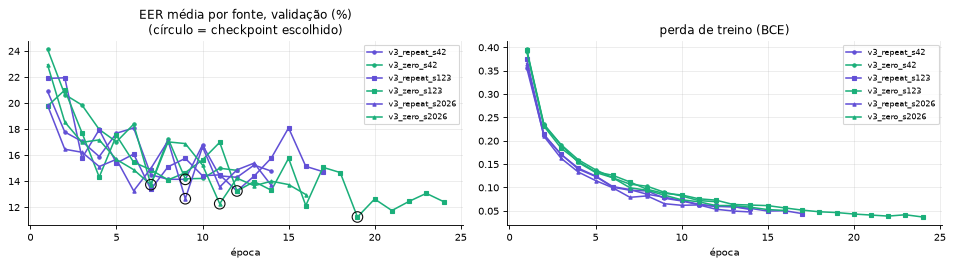

In [11]:
if HIST:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    for exp, h in HIST.items():
        cfg = EXPERIMENTOS[exp]
        kw = dict(color=COR_COND[cfg["short_audio_mode"]], marker=MARCA_SEED.get(cfg["seed"], "o"), ms=3, lw=1.4, label=exp)
        i = h["EER média por fonte (val)"].idxmin()
        axes[0].plot(h["época"], 100 * h["EER média por fonte (val)"], **kw)
        axes[0].scatter([h.loc[i, "época"]], [100 * h.loc[i, "EER média por fonte (val)"]], s=90,
                        facecolors="none", edgecolors="#0b0b0b", zorder=3)
        axes[1].plot(h["época"], h["perda treino"], **kw)
    axes[0].set_title("EER média por fonte, validação (%)\n(círculo = checkpoint escolhido)")
    axes[1].set_title("perda de treino (BCE)")
    for ax in axes:
        ax.set_xlabel("época")
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()
else:
    print("nenhuma execução concluída: sem curvas para mostrar.")

**Conclusão do treino:**
- As seis execuções pararam pelo **early stopping** (5 épocas sem melhorar a EER média por fonte); nenhuma chegou ao teto de 30 épocas. Épocas (melhor): `repeat` 14 (9), 17 (12) e 14 (9); `zero` 12 (7), 24 (19) e 16 (11), nas seeds 42, 123 e 2026.
- **Nenhuma foi retomada** (`treino_retomado_nas_epocas` vazio nos seis marcadores), e todas usaram o mesmo código (commit `bba9b9c` com as mesmas mudanças não commitadas).
- As curvas das duas condições se sobrepõem: a diferença **entre seeds** da mesma condição é do mesmo tamanho que a diferença **entre condições**.
- **Tempo de treino:** 19 a 45 min por execução, 3,4 h somando as seis (soma das épocas). A **época 13 do `v3_zero_s2026` levou 1.331 s** (as vizinhas, ~80 s) e a 15 levou 241 s: lentidão do computador, sem interrupção nem retomada. **Não muda nenhum resultado**, porque o tempo não entra em nenhuma conta do treino (mesmas épocas, mesmos áudios, mesmos sorteios). As três primeiras execuções tiveram épocas de ~150 a 165 s, e as três últimas de ~80 s; a causa não foi medida.
- **Pico de memória:** 13,1 a 13,2 GB por execução (processo + workers), acima dos 7,3 a 7,8 GB medidos na v2 (`docs/HISTORICO_VERSOES.md`, seção h); a causa não foi investigada.

## 7. Avaliação

### 7.1 Métricas, limiar e janelas (iguais à v2)

- **AUC e EER** são as métricas principais: não dependem de limiar nem da proporção real/fake.
- **Recall de fake e falso alarme** dependem do limiar. O limiar de cada execução é a **EER da validação inteira, avaliada por janelas**, o **mesmo procedimento nos dois braços**. Como cada execução tem o seu limiar, recall e falso alarme **não** são diretamente comparáveis entre execuções. Nenhum limiar é ajustado no dev_shift nem no teste.
- **Janelas:** cada áudio é cortado em janelas de 4 s com passo de 2 s, e a nota é a média dos logits. Um áudio com menos de 4 s vira **uma janela só**, completada com a política da execução; para ele, janelas e recorte central dão a mesma nota.

### 7.2 Notas da validação e do dev_shift

**O que faz:** lê as notas por áudio que o script gravou para cada execução concluída e confere que são da mesma configuração do marcador (`config_id`), da política certa e da amostra esperada, e que não há NaN nem infinito.
**Por quê:** a avaliação usa só o que foi calculado com o modelo congelado, no processo de treino.

In [12]:
NOTAS = {}
for exp in CONCLUIDAS:
    for conjunto, amostra in [("val", val_df), ("dev_shift", dev_df)]:
        n_ = pd.read_parquet(caminho_notas(exp, conjunto))
        assert n_["path"].tolist() == amostra["path"].tolist(), f"{exp} {conjunto}: amostra diferente"
        assert n_.config_id.eq(MARC[exp]["config_id"]).all(), f"{exp} {conjunto}: config_id diferente do marcador"
        assert n_.short_audio_mode.eq(EXPERIMENTOS[exp]["short_audio_mode"]).all()
        assert np.isfinite(n_[["z_janelas", "z_central"]].values).all()
        NOTAS[(exp, conjunto)] = n_
print(f"notas lidas: {len(NOTAS)} arquivos de {len(CONCLUIDAS)} execuções concluídas")

notas lidas: 12 arquivos de 6 execuções concluídas


### 7.3 Resultado de cada execução (validação e dev_shift)

**O que faz:** para cada execução: limiar, EER global e EER por fonte da validação, e AUC, EER, falso alarme e recall do dev_shift (janelas e central).
**Por quê:** são os números que decidem. Todas as execuções aparecem, nenhuma é escolhida pela melhor seed.

In [13]:
MODOS = ["janelas", "central"]
LIMIAR, linhas = {}, []
for exp in CONCLUIDAS:
    v, d = NOTAS[(exp, "val")], NOTAS[(exp, "dev_shift")]
    for modo in MODOS:
        LIMIAR[(exp, modo)] = eer_e_limiar(v.label.values, v[f"z_{modo}"].values)[1]
    media, por_fonte = eer_media_por_fonte(v.label.values, v.z_janelas.values, v.source_dataset.values)
    linha = {"execução": exp, "condição": EXPERIMENTOS[exp]["short_audio_mode"], "seed": EXPERIMENTOS[exp]["seed"],
             "limiar janelas (prob.)": float(sigmoide(LIMIAR[(exp, "janelas")])),
             "val: EER média por fonte (checkpoint)": MARC[exp]["val_eer_media_por_fonte"],
             "val: EER global (janelas)": eer_e_limiar(v.label.values, v.z_janelas.values)[0],
             **{f"val: EER {s} (janelas)": e for s, e in por_fonte.items()}}
    for modo in MODOS:
        m = metricas(d.label.values, d[f"z_{modo}"].values, LIMIAR[(exp, modo)])
        linha.update({f"dev_shift ({modo}): {k}": m[k] for k in ["AUC", "EER", "falso alarme", "recall fake"]})
    linhas.append(linha)
TAB_DEC = pd.DataFrame(linhas).set_index("execução") if linhas else pd.DataFrame()
if len(TAB_DEC):
    vis = TAB_DEC.drop(columns=["condição", "seed"]).T.astype(object)
    for i in vis.index:
        vis.loc[i] = vis.loc[i].map(lambda x: f"{x:.3f}" if ("AUC" in i or "limiar" in i) else f"{100 * x:.1f}%")
    display(vis)
else:
    print("nenhuma execução concluída.")

execução,v3_repeat_s42,v3_zero_s42,v3_repeat_s123,v3_zero_s123,v3_repeat_s2026,v3_zero_s2026
limiar janelas (prob.),0.641,0.919,0.787,0.128,0.627,0.957
val: EER média por fonte (checkpoint),14.1%,13.7%,13.2%,11.2%,12.6%,12.3%
val: EER global (janelas),1.2%,2.2%,1.7%,1.0%,1.2%,1.1%
val: EER codecfake_plus (janelas),30.4%,27.5%,29.8%,25.9%,28.1%,25.6%
val: EER dfadd (janelas),0.2%,0.4%,0.4%,0.1%,0.1%,0.2%
val: EER shiftyspeech (janelas),7.0%,11.3%,7.5%,6.2%,7.7%,6.8%
dev_shift (janelas): AUC,0.241,0.274,0.378,0.146,0.228,0.377
dev_shift (janelas): EER,69.6%,66.5%,59.2%,79.4%,70.5%,57.7%
dev_shift (janelas): falso alarme,91.3%,90.0%,80.1%,95.6%,95.3%,71.7%
dev_shift (janelas): recall fake,78.1%,70.1%,80.7%,68.5%,81.7%,60.5%


### 7.4 Comparação pareada por seed (a comparação principal, pré-registrada)

**O que faz:** para cada seed com as duas condições concluídas, calcula Δ = zero − repeat da EER e da AUC do dev_shift (janelas). Mostra os Δ, a média, o desvio padrão, e a **amplitude entre as seeds do `v3_repeat`** (maior EER − menor EER). Aplica a regra pré-registrada: só é efeito se os três Δ tiverem o mesmo sinal **e** |média dos Δ| for maior que essa amplitude. Faz o mesmo, fonte por fonte, na EER da validação (para achar regressões).
**Por quê:** comparar na mesma seed tira do caminho a parte do acaso que é comum às duas condições (mesmos áudios, mesmos trechos, mesma inicialização). A amplitude entre seeds mostra o tamanho do acaso que sobra.

> ⚠️ **Fora da trilha (comparação pareada e dispersão entre seeds):** com só três seeds não há teste estatístico confiável; por isso a regra é simples e foi fixada antes dos resultados. Δ < 0 na EER = `zero` erra menos; Δ > 0 na AUC = `zero` ordena melhor.

In [14]:
def regra(deltas, amplitude_ref, menor_melhor=True):
    if len(deltas) < len(SEEDS_TREINO):
        return f"incompleto ({len(deltas)} de {len(SEEDS_TREINO)} seeds pareadas)"
    sinais = set(np.sign(deltas))
    media = float(np.mean(deltas))
    if len(sinais) == 1 and 0 not in sinais and abs(media) > amplitude_ref:
        melhor = (media < 0) if menor_melhor else (media > 0)
        return "efeito: zero " + ("MELHOR" if melhor else "PIOR") + " que repeat"
    return "dentro do acaso entre seeds (não demonstrado)"


PAR = []
for s in SEEDS_TREINO:
    r, z = f"v3_repeat_s{s}", f"v3_zero_s{s}"
    if r in TAB_DEC.index and z in TAB_DEC.index:
        PAR.append({"seed": s,
                    "EER repeat": TAB_DEC.loc[r, "dev_shift (janelas): EER"], "EER zero": TAB_DEC.loc[z, "dev_shift (janelas): EER"],
                    "AUC repeat": TAB_DEC.loc[r, "dev_shift (janelas): AUC"], "AUC zero": TAB_DEC.loc[z, "dev_shift (janelas): AUC"]})
PAR = pd.DataFrame(PAR)
if len(PAR):
    PAR["Δ EER (zero − repeat)"] = PAR["EER zero"] - PAR["EER repeat"]
    PAR["Δ AUC (zero − repeat)"] = PAR["AUC zero"] - PAR["AUC repeat"]
    show_md(PAR.round(4), index=False)
    rep = TAB_DEC[TAB_DEC["condição"] == "repeat"]
    amp_eer = float(rep["dev_shift (janelas): EER"].max() - rep["dev_shift (janelas): EER"].min())
    amp_auc = float(rep["dev_shift (janelas): AUC"].max() - rep["dev_shift (janelas): AUC"].min())
    RESUMO_PAR = pd.DataFrame([
        {"métrica (dev_shift, janelas)": "EER", "média Δ": PAR["Δ EER (zero − repeat)"].mean(),
         "desvio Δ": PAR["Δ EER (zero − repeat)"].std(ddof=1), "amplitude entre seeds do repeat": amp_eer,
         "conclusão pela regra": regra(PAR["Δ EER (zero − repeat)"].values, amp_eer, True)},
        {"métrica (dev_shift, janelas)": "AUC", "média Δ": PAR["Δ AUC (zero − repeat)"].mean(),
         "desvio Δ": PAR["Δ AUC (zero − repeat)"].std(ddof=1), "amplitude entre seeds do repeat": amp_auc,
         "conclusão pela regra": regra(PAR["Δ AUC (zero − repeat)"].values, amp_auc, False)}])
    show_md(RESUMO_PAR.round(4), index=False)
    por_cond = TAB_DEC.groupby("condição")[["dev_shift (janelas): EER", "dev_shift (janelas): AUC",
                                            "val: EER média por fonte (checkpoint)"]].agg(["mean", "std", "min", "max", "count"])
    display(por_cond.round(4))

    # regressões na validação, fonte por fonte (mesma regra)
    fontes = [c for c in TAB_DEC.columns if c.startswith("val: EER ") and "(janelas)" in c and "global" not in c]
    linhas = []
    for c in fontes:
        deltas = [TAB_DEC.loc[f"v3_zero_s{s}", c] - TAB_DEC.loc[f"v3_repeat_s{s}", c] for s in PAR.seed]
        amp = float(rep[c].max() - rep[c].min())
        linhas.append({"fonte (validação)": c.replace("val: EER ", ""), "Δ por seed (pontos)": ", ".join(f"{100 * float(x):+.2f}" for x in deltas),
                       "média Δ (pontos)": round(100 * np.mean(deltas), 2), "amplitude repeat (pontos)": round(100 * amp, 2),
                       "conclusão pela regra": regra(np.array(deltas), amp, True)})
    show_md(pd.DataFrame(linhas), index=False)
else:
    print("nenhuma seed com as duas condições concluídas: comparação pareada pendente.")

|   seed |   EER repeat |   EER zero |   AUC repeat |   AUC zero |   Δ EER (zero − repeat) |   Δ AUC (zero − repeat) |
|-------:|-------------:|-----------:|-------------:|-----------:|------------------------:|------------------------:|
|     42 |       0.696  |     0.6647 |       0.2413 |     0.274  |                 -0.0313 |                  0.0327 |
|    123 |       0.5923 |     0.7937 |       0.3775 |     0.1455 |                  0.2015 |                 -0.232  |
|   2026 |       0.7051 |     0.577  |       0.2284 |     0.3773 |                 -0.1281 |                  0.149  |

| métrica (dev_shift, janelas)   |   média Δ |   desvio Δ |   amplitude entre seeds do repeat | conclusão pela regra                          |
|:-------------------------------|----------:|-----------:|----------------------------------:|:----------------------------------------------|
| EER                            |    0.014  |     0.1694 |                            0.1128 | dentro do acaso entre seeds (não demonstrado) |
| AUC                            |   -0.0168 |     0.1952 |                            0.1491 | dentro do acaso entre seeds (não demonstrado) |

dev_shift (janelas): EER                                \
                             mean     std     min     max count   
condição                                                          
repeat                     0.6644  0.0627  0.5923  0.7051     3   
zero                       0.6785  0.1090  0.5770  0.7937     3   

         dev_shift (janelas): AUC                                \
                             mean     std     min     max count   
condição                                                          
repeat                     0.2824  0.0826  0.2284  0.3775     3   
zero                       0.2656  0.1161  0.1455  0.3773     3   

         val: EER média por fonte (checkpoint)                                
                                          mean     std     min     max count  
condição                                                                      
repeat                                  0.1334  0.0075  0.1265  0.1414     3  
zero                                    0.1241  0.0125  0.1125  0.1373     3

| fonte (validação)        | Δ por seed (pontos)   |   média Δ (pontos) |   amplitude repeat (pontos) | conclusão pela regra                          |
|:-------------------------|:----------------------|-------------------:|----------------------------:|:----------------------------------------------|
| codecfake_plus (janelas) | -2.85, -3.92, -2.55   |              -3.11 |                        2.28 | efeito: zero MELHOR que repeat                |
| dfadd (janelas)          | +0.23, -0.22, +0.13   |               0.05 |                        0.27 | dentro do acaso entre seeds (não demonstrado) |
| shiftyspeech (janelas)   | +4.31, -1.30, -0.94   |               0.69 |                        0.69 | dentro do acaso entre seeds (não demonstrado) |

### 7.5 Diagnóstico por duração original

**O que faz:** para cada execução, na validação e no dev_shift, calcula por faixa de duração original (< 2 s, 2 a < 4 s, ≥ 4 s): tamanho, reais e fakes, e AUC e EER **só quando a faixa tem as duas classes**. Depois tira a média por condição e o Δ pareado (zero − repeat) por faixa.
**Por quê:** se o zero-padding ajudar, a melhora deve aparecer **nos curtos**. Nos ≥ 4 s a entrada é idêntica nas duas condições, então uma diferença ali mede o acaso ou um efeito indireto do treino (o modelo aprendeu outra coisa com os curtos). Uma perda nos ≥ 4 s é um sinal de alerta.

In [15]:
linhas = []
for exp in CONCLUIDAS:
    for conjunto in ["val", "dev_shift"]:
        t = metricas_por_duracao(NOTAS[(exp, conjunto)], "z_janelas", LIMIAR[(exp, "janelas")])
        linhas.append(t.assign(execução=exp, condição=EXPERIMENTOS[exp]["short_audio_mode"],
                               seed=EXPERIMENTOS[exp]["seed"], conjunto=conjunto))
DUR = pd.concat(linhas, ignore_index=True) if linhas else pd.DataFrame()
if len(DUR):
    tam = DUR.drop_duplicates(["conjunto", "faixa"])[["conjunto", "faixa", "n", "n real", "n fake", "% fake"]]
    show_md(tam.round(1), index=False)
    media = DUR.pivot_table(index=["conjunto", "faixa"], columns="condição", values=["AUC", "EER"],
                            aggfunc="mean", observed=True, sort=False)
    display(media.round(3).rename_axis(columns=["métrica (média das seeds)", "condição"]))
    d_par = []
    for (conj, faixa, s), g in DUR.groupby(["conjunto", "faixa", "seed"], sort=False):
        if set(g["condição"]) == set(CONDICOES):
            gz, gr = g[g["condição"] == "zero"].iloc[0], g[g["condição"] == "repeat"].iloc[0]
            d_par.append({"conjunto": conj, "faixa": faixa, "seed": s, "Δ AUC": gz.AUC - gr.AUC, "Δ EER": gz.EER - gr.EER})
    if d_par:
        d_par = pd.DataFrame(d_par)
        display(d_par.pivot_table(index=["conjunto", "faixa"], columns="seed", values=["Δ EER", "Δ AUC"], sort=False).round(3))
else:
    print("nenhuma execução concluída.")

| conjunto   | faixa     |     n |   n real |   n fake |   % fake |
|:-----------|:----------|------:|---------:|---------:|---------:|
| val        | < 2 s     |   886 |      270 |      616 |     69.5 |
| val        | 2 a < 4 s | 25300 |     7189 |    18111 |     71.6 |
| val        | ≥ 4 s     | 25003 |     8271 |    16732 |     66.9 |
| dev_shift  | < 2 s     |  2420 |     2067 |      353 |     14.6 |
| dev_shift  | 2 a < 4 s |  4531 |     3772 |      759 |     16.8 |
| dev_shift  | ≥ 4 s     |  3663 |     2794 |      869 |     23.7 |

métrica (média das seeds)    AUC           EER       
condição                  repeat   zero repeat   zero
conjunto  faixa                                      
val       < 2 s            0.997  0.992  0.028  0.047
          2 a < 4 s        0.999  0.999  0.011  0.011
          ≥ 4 s            0.997  0.998  0.016  0.014
dev_shift < 2 s            0.215  0.371  0.729  0.615
          2 a < 4 s        0.265  0.262  0.682  0.682
          ≥ 4 s            0.355  0.216  0.607  0.713

Δ EER                Δ AUC              
seed                  42     123    2026   42     123    2026
conjunto  faixa                                              
val       < 2 s      0.033  0.003  0.022 -0.009 -0.001 -0.003
          2 a < 4 s  0.005 -0.005  0.000 -0.001  0.000 -0.000
          ≥ 4 s      0.007 -0.011 -0.002 -0.001  0.002  0.000
dev_shift < 2 s     -0.128  0.135 -0.351  0.151 -0.128  0.444
          2 a < 4 s -0.054  0.186 -0.132  0.046 -0.214  0.159
          ≥ 4 s      0.079  0.283 -0.047 -0.104 -0.334  0.018

**Conclusão da avaliação (validação e dev_shift), pela regra pré-registrada (7.4):**
- **Comparação principal (EER do dev_shift, janelas):** Δ = zero − repeat de **−3,1, +20,1 e −12,8 pontos** (seeds 42, 123 e 2026); média +1,4 pontos, desvio 16,9. Os três Δ **não** têm o mesmo sinal, e |média| (1,4) é menor que a amplitude entre as seeds do `repeat` (11,3 pontos). **Resultado: diferença dentro do acaso entre seeds, não demonstrada.**
- **AUC do dev_shift:** Δ de +0,033, −0,232 e +0,149; média −0,017 (desvio 0,195), contra amplitude de 0,149 no `repeat`. **Dentro do acaso.** O recorte central dá o mesmo quadro (Δ EER −2,3, +20,1 e −11,7 pontos).
- **As seis AUCs do dev_shift ficaram abaixo de 0,5** (de 0,146 a 0,378): nas duas condições e em todas as seeds, o modelo continua ordenando o In-the-Wild ao contrário.
- **Validação, fonte por fonte (busca de regressões): nenhuma regressão.** DFADD (Δ +0,2, −0,2, +0,1 pontos) e ShiftySpeech (+4,3, −1,3, −0,9) ficam dentro do acaso. **No CodecFake+ os três Δ são negativos** (−2,9, −3,9 e −2,5 pontos; média −3,1) e passam a amplitude do `repeat` (2,3 pontos): pela mesma regra, `zero` erra menos no CodecFake+ da validação. Ressalvas: são só 352 áudios; a melhora aparece também nos ≥ 4 s, onde a entrada é igual nas duas condições (se for real, é um efeito indireto do treino, não da entrada); e é um critério complementar, que não decide a versão. A EER média por fonte (a do checkpoint) cai 0,4, 2,0 e 0,4 pontos, dentro da amplitude do `repeat` (1,5 pontos).
- **Por duração:** na validação, `zero` fica um pouco pior abaixo de 2 s nas três seeds (EER +3,3, +0,3 e +2,2 pontos; AUC média 0,992 contra 0,997; 886 áudios) e igual nas outras faixas. No dev_shift, a média de `zero` é melhor nos curtos (AUC 0,371 contra 0,215 abaixo de 2 s) e pior nos ≥ 4 s (0,216 contra 0,355), mas **os Δ por seed trocam de sinal nas três faixas** (< 2 s: +0,15, −0,13, +0,44; ≥ 4 s: −0,10, −0,33, +0,02). A perda média nos ≥ 4 s, que o pré-registro mandava checar, também fica dentro do acaso. É uma pista, não um efeito.
- **Limiares:** muito diferentes entre execuções (0,13 a 0,96 em probabilidade), por isso recall e falso alarme não são comparados entre elas.

### 7.6 Registro em `results/experiments.csv` (validação e dev_shift)

**O que faz:** quando as seis execuções estão concluídas, grava uma linha por execução, conjunto e banco (validação inteira, cada fonte da validação e dev_shift; janelas e central) em `results/experiments.csv`, **sem apagar as linhas da v2** (só as linhas da v3 desse tipo são substituídas). No QUICK, grava em `results/experiments_quick.csv`.
**Por quê:** é a tabela que as próximas versões consultam; todas as execuções entram, nenhuma é escolhida.

In [16]:
HOJE = date.today().isoformat()


def linha_csv(exp, conjunto, banco, tipo, modo, g):
    m = metricas(g.label.values, g[f"z_{modo}"].values, LIMIAR[(exp, modo)])
    return {"versão": VERSAO, "experimento": exp, "descrição": EXPERIMENTOS[exp]["descricao"],
            "condição": EXPERIMENTOS[exp]["short_audio_mode"], "seed": EXPERIMENTOS[exp]["seed"],
            "conjunto": conjunto, "banco": banco, "tipo": tipo, "avaliação": modo, **m,
            "limiar (prob.)": float(sigmoide(LIMIAR[(exp, modo)])), "limiar (logit)": LIMIAR[(exp, modo)],
            "época escolhida": MARC[exp]["melhor_epoca"],
            "EER média por fonte val (checkpoint)": MARC[exp]["val_eer_media_por_fonte"],
            "tempo de treino (min)": MARC[exp]["minutos_treino"], "data": HOJE}


def gravar_linhas_v3(novas, conjuntos):
    # substitui só as linhas da v3 dos `conjuntos` dados; o resto (v2, outras linhas da v3) fica
    from src.arquivos import salvar_csv
    antigo = pd.read_csv(EXPERIMENTS_CSV) if EXPERIMENTS_CSV.exists() else pd.DataFrame()
    if len(antigo):
        antigo = antigo[~((antigo["versão"] == VERSAO) & antigo["conjunto"].isin(conjuntos))]
    salvar_csv(pd.concat([antigo, pd.DataFrame(novas)], ignore_index=True), EXPERIMENTS_CSV)


if TODAS_CONCLUIDAS:
    REG = []
    for exp in EXPERIMENTOS:
        for modo in MODOS:
            v = NOTAS[(exp, "val")]
            REG.append(linha_csv(exp, "validação", "todas as fontes", "validação", modo, v))
            for s, g in v.groupby("source_dataset"):
                REG.append(linha_csv(exp, "validação", s, "validação", modo, g))
            REG.append(linha_csv(exp, "dev_shift", "in_the_wild", "decisão entre versões", modo, NOTAS[(exp, "dev_shift")]))
    gravar_linhas_v3(REG, ["validação", "dev_shift"])
    print(f"{len(REG)} linhas da v3 (validação e dev_shift) gravadas em {EXPERIMENTS_CSV}")
else:
    print(f"nada gravado em {EXPERIMENTS_CSV}: faltam execuções ({len(CONCLUIDAS)} de {len(EXPERIMENTOS)} concluídas).")

72 linhas da v3 (validação e dev_shift) gravadas em results\experiments.csv


### 7.7 Teste final (etapa separada, uma única vez)

**O que faz:** com `AVALIAR_TESTE_FINAL = True` (e fora do QUICK), e **só** com as seis execuções concluídas, calcula as notas do teste final (até `TEST_MAX_PER_CLASS` áudios por classe e banco; In-the-Wild só `test_final`) para **todas** as execuções, com a política de áudio curto de cada uma e o limiar fixado na validação, e grava as métricas em `results/experiments.csv`. As notas ficam em `results/<exp>_notas_teste.parquet`; com `REUSAR = True`, uma segunda execução só as lê, então o teste de cada execução é calculado **uma vez**.
**Por quê:** o teste só reporta. Ele acontece **depois** da análise de validação/dev_shift (seções 7.3 a 7.5 e conclusões escritas), não escolhe condição nem seed, e todas as condições e seeds são reportadas. Nenhum limiar é ajustado aqui.

Com `AVALIAR_TESTE_FINAL = False` (o padrão), esta célula não lê nada do teste.

In [17]:
TESTES = ["in_the_wild", "llamapartialspoof", "brspeech_df", "asvspoof2019_la", "asvspoof2021_df", "coraa"]
TIPO = {"in_the_wild": "principal (só test_final)", "llamapartialspoof": "principal", "brspeech_df": "principal (pt)",
        "asvspoof2019_la": "secundário", "asvspoof2021_df": "secundário", "coraa": "falso alarme pt-BR"}

if not AVALIAR_TESTE_FINAL or QUICK:
    print("teste final NÃO avaliado (AVALIAR_TESTE_FINAL = False ou QUICK = True). Nada do teste foi consultado.")
elif not TODAS_CONCLUIDAS:
    print("teste final NÃO avaliado: as seis execuções precisam estar concluídas antes.")
else:
    from src.arquivos import salvar_parquet
    teste_df, teste_full = amostra_teste(df, HP, TESTES)
    REG_T = []
    for exp in EXPERIMENTOS:
        arq = caminho_notas(exp, "teste")
        salvo = pd.read_parquet(arq) if (REUSAR and arq.exists()) else None
        if salvo is not None and salvo["path"].tolist() == teste_df["path"].tolist():
            t = salvo
            print(f"{exp}: notas do teste lidas do disco (já calculadas)")
        else:
            modelo, ck, modo = carregar_modelo(caminho_ckpt(exp), DEVICE)
            assert modo == EXPERIMENTOS[exp]["short_audio_mode"]
            t0 = time.time()
            t = calcular_notas(modelo, logmel, teste_df, HP, modo, DEVICE).assign(experimento=exp, short_audio_mode=modo)
            salvar_parquet(t, arq)
            print(f"{exp}: teste calculado em {(time.time() - t0) / 60:.1f} min -> {arq}")
            del modelo
        for modo_ in MODOS:
            for s in TESTES:
                REG_T.append(linha_csv(exp, "test_final", s, TIPO[s], modo_, t[t.source_dataset == s]))
    gravar_linhas_v3(REG_T, ["test_final"])
    TAB_T = pd.DataFrame(REG_T)
    TAB_T = TAB_T[TAB_T["avaliação"] == "janelas"]
    display(TAB_T.pivot_table(index="banco", columns="experimento", values=["AUC", "EER", "falso alarme"]).round(3))
    display(TAB_T.groupby(["banco", "condição"])[["AUC", "EER", "falso alarme"]].agg(["mean", "std"]).round(3))
    print("⚠️ coraa: só tem reais; vale só o falso alarme (com o limiar de cada execução).")

teste final NÃO avaliado (AVALIAR_TESTE_FINAL = False ou QUICK = True). Nada do teste foi consultado.


## 8. Experimentos e conclusões

Escrita **só** com os números das seções 6 e 7 (validação e dev_shift), pela regra pré-registrada, e **com o teste final ainda não avaliado** (`AVALIAR_TESTE_FINAL = False`). Quando o teste final for avaliado, numa etapa separada, os números dele entram aqui como relato, sem mudar nenhuma conclusão.

### 8.1 Os seis experimentos

**O que faz:** junta numa tabela, lida dos marcadores e das notas no disco, os números que decidem (EER média por fonte e EER global da validação; EER e AUC do dev_shift por janelas), o tempo e o pico de memória de cada execução. Depois mostra a média e o desvio por condição e a **régua do ruído**: o mínimo e o máximo da AUC do dev_shift entre as seeds.
**Por quê:** é o resumo da versão num lugar só, sem número digitado à mão.

In [18]:
if TODAS_CONCLUIDAS:
    RES = pd.DataFrame([{
        "execução": exp, "condição": cfg["short_audio_mode"], "seed": cfg["seed"],
        "épocas (melhor)": f"{MARC[exp]['epocas']} ({MARC[exp]['melhor_epoca']})",
        "val: EER média por fonte (checkpoint)": MARC[exp]["val_eer_media_por_fonte"],
        "val: EER global (janelas)": TAB_DEC.loc[exp, "val: EER global (janelas)"],
        "dev_shift: EER": TAB_DEC.loc[exp, "dev_shift (janelas): EER"],
        "dev_shift: AUC": TAB_DEC.loc[exp, "dev_shift (janelas): AUC"],
        "min de treino": MARC[exp]["minutos_treino"],
        "época mais lenta (s)": float(HIST[exp]["segundos"].max()),
        "pico de memória (GB)": MARC[exp]["pico_memoria_gb_processo_e_workers"]}
        for exp, cfg in EXPERIMENTOS.items()])
    vis = RES.copy()
    for c in ["val: EER média por fonte (checkpoint)", "val: EER global (janelas)", "dev_shift: EER"]:
        vis[c] = vis[c].map(lambda x: f"{100 * x:.1f}%")
    vis["dev_shift: AUC"] = vis["dev_shift: AUC"].map(lambda x: f"{x:.3f}")
    vis["época mais lenta (s)"] = vis["época mais lenta (s)"].round(0).astype(int)
    show_md(vis, index=False)

    num = ["val: EER média por fonte (checkpoint)", "val: EER global (janelas)", "dev_shift: EER", "dev_shift: AUC",
           "min de treino", "pico de memória (GB)"]
    display(RES.groupby("condição")[num].agg(["mean", "std"]).round(4))

    REGUA = RES.groupby("condição")["dev_shift: AUC"].agg(["min", "max"])
    REGUA.loc["as seis"] = [RES["dev_shift: AUC"].min(), RES["dev_shift: AUC"].max()]
    REGUA["amplitude (máx − mín)"] = REGUA["max"] - REGUA["min"]
    show_md(REGUA.round(3).rename_axis("régua do ruído: AUC do dev_shift (janelas)"))
    print(f"execuções com AUC do dev_shift abaixo de 0,5: {(RES['dev_shift: AUC'] < 0.5).sum()} de {len(RES)}")
    print(f"tempo de treino somado: {RES['min de treino'].sum() / 60:.1f} h")
else:
    print("faltam execuções: resumo pendente.")

| execução        | condição   |   seed | épocas (melhor)   | val: EER média por fonte (checkpoint)   | val: EER global (janelas)   | dev_shift: EER   |   dev_shift: AUC |   min de treino |   época mais lenta (s) |   pico de memória (GB) |
|:----------------|:-----------|-------:|:------------------|:----------------------------------------|:----------------------------|:-----------------|-----------------:|----------------:|-----------------------:|-----------------------:|
| v3_repeat_s42   | repeat     |     42 | 14 (9)            | 14.1%                                   | 1.2%                        | 69.6%            |            0.241 |           35.91 |                    164 |                  13.15 |
| v3_zero_s42     | zero       |     42 | 12 (7)            | 13.7%                                   | 2.2%                        | 66.5%            |            0.274 |           28.16 |                    166 |                  13.14 |
| v3_repeat_s123  | repeat     |    123 | 17 (12)           | 13.2%                                   | 1.7%                        | 59.2%            |            0.378 |           41.24 |                    174 |                  13.16 |
| v3_zero_s123    | zero       |    123 | 24 (19)           | 11.2%                                   | 1.0%                        | 79.4%            |            0.146 |           33.28 |                    108 |                  13.12 |
| v3_repeat_s2026 | repeat     |   2026 | 14 (9)            | 12.6%                                   | 1.2%                        | 70.5%            |            0.228 |           19.02 |                     90 |                  13.13 |
| v3_zero_s2026   | zero       |   2026 | 16 (11)           | 12.3%                                   | 1.1%                        | 57.7%            |            0.377 |           45.23 |                   1331 |                  13.11 |

val: EER média por fonte (checkpoint)          \
                                          mean     std   
condição                                                 
repeat                                  0.1334  0.0075   
zero                                    0.1241  0.0125   

         val: EER global (janelas)         dev_shift: EER          \
                              mean     std           mean     std   
condição                                                            
repeat                      0.0135  0.0029         0.6644  0.0627   
zero                        0.0142  0.0064         0.6785  0.1090   

         dev_shift: AUC         min de treino          pico de memória (GB)  \
                   mean     std          mean      std                 mean   
condição                                                                      
repeat           0.2824  0.0826       32.0567  11.6004              13.1467   
zero             0.2656  0.1161       35.5567   8.7598              13.1233   

                  
             std  
condição          
repeat    0.0153  
zero      0.0153

| régua do ruído: AUC do dev_shift (janelas)   |   min |   max |   amplitude (máx − mín) |
|:---------------------------------------------|------:|------:|------------------------:|
| repeat                                       | 0.228 | 0.378 |                   0.149 |
| zero                                         | 0.146 | 0.377 |                   0.232 |
| as seis                                      | 0.146 | 0.378 |                   0.232 |

execuções com AUC do dev_shift abaixo de 0,5: 6 de 6
tempo de treino somado: 3.4 h


**Conclusão (8.1):** a tabela repete, por execução, o que as seções 7.3 e 7.4 já mostraram. As médias por condição são parecidas (dev_shift EER 66,4% × 67,8%, AUC 0,282 × 0,266, `repeat` × `zero`), e o desvio entre seeds (0,08 a 0,12 de AUC) é maior que a diferença entre as médias.

### 8.2 O que a regra pré-registrada diz

| critério (pré-registrado) | Δ por seed (42 / 123 / 2026) | média | régua (amplitude do `repeat`) | resultado |
|:--|:--|--:|--:|:--|
| **principal:** EER do dev_shift (janelas) | −3,1 / +20,1 / −12,8 pontos | +1,4 pontos | 11,3 pontos | sinais trocados: **dentro do acaso** |
| AUC do dev_shift (janelas) | +0,033 / −0,232 / +0,149 | −0,017 | 0,149 | sinais trocados: **dentro do acaso** |
| validação, CodecFake+ (EER) | −2,9 / −3,9 / −2,5 pontos | −3,1 pontos | 2,3 pontos | passa a regra: `zero` melhor (352 áudios; complementar) |
| validação, DFADD (EER) | +0,2 / −0,2 / +0,1 pontos | +0,05 pontos | 0,3 pontos | dentro do acaso |
| validação, ShiftySpeech (EER) | +4,3 / −1,3 / −0,9 pontos | +0,7 pontos | 0,7 pontos | dentro do acaso |

**A diferença entre `zero` e `repeat` no dev_shift está dentro do ruído.** Nenhuma regressão na validação. O único critério que passa a regra é o CodecFake+ da validação, que é complementar, pequeno e aparece também onde a entrada não muda (≥ 4 s); ele não basta para dizer que o zero-padding generaliza melhor.

### 8.3 Diagnóstico por duração (o que se esperava × o que aconteceu)

- **Esperado se a repetição fosse o problema:** `zero` melhor nos curtos do dev_shift e igual nos ≥ 4 s.
- **Aconteceu:** na média, `zero` melhor nos curtos (AUC 0,371 × 0,215 abaixo de 2 s) e **pior** nos ≥ 4 s (0,216 × 0,355), mas com os Δ por seed trocando de sinal em todas as faixas. Na validação, `zero` um pouco pior abaixo de 2 s (EER 4,7% × 2,8%, 886 áudios) e igual no resto. Todas as faixas do dev_shift têm as duas classes (14,6%, 16,8% e 23,7% de fakes).
- **Leitura honesta:** o padrão médio nos curtos é o que a hipótese preveria, mas a perda nos longos (onde a entrada é a mesma) e a dispersão entre seeds mostram que não dá para separar isso do acaso com três seeds.

### 8.4 A régua do ruído (referência para as próximas versões)

Com **a mesma receita e só a seed mudando**, a AUC do dev_shift (janelas) foi de **0,228 a 0,378 no `repeat`** (amplitude 0,149) e de **0,146 a 0,377 no `zero`** (amplitude 0,232); a EER, de 59,2% a 70,5% e de 57,7% a 79,4%. Consequências:
- Uma diferença de AUC no dev_shift menor que **~0,15** entre duas execuções únicas **não diz nada**. A estimativa de acaso da v2 (~0,06, do v2a) estava subestimada, e as diferenças entre v1r, v2a e v2b (0,325 / 0,386 / 0,389) cabem com folga nessa régua.
- Na validação, a régua é bem menor: 1,5 pontos na EER média por fonte (checkpoint) e 2,3 pontos no CodecFake+ (amplitude do `repeat`).
- Comparar versões daqui em diante exige várias seeds por condição.

### 8.5 Conclusão em uma frase

Trocar a repetição por zeros **não mudou o dev_shift de forma demonstrável** (Δ EER pareado −3,1, +20,1 e −12,8 pontos, sinais trocados), as seis execuções continuam com AUC abaixo de 0,5, e o que a v3 mais mostrou foi o tamanho do acaso entre seeds (AUC do dev_shift de 0,146 a 0,378 com a mesma receita).

### 8.6 Tempo e memória

Seis treinos de 19 a 45 min (3,4 h somadas), um processo por execução, RTX 4060 8 GB, 4 workers; pico de 13,1 a 13,2 GB por processo. A época 13 do `v3_zero_s2026` levou 1.331 s (lentidão do computador, sem retomada), sem efeito nos resultados.

### 8.7 Limitações

- Três seeds por condição medem o acaso do treino só de forma grosseira, e o acaso medido é grande.
- O dev_shift tem 16 locutores, 18,7% de fakes e é dominado por Obama e Trump.
- A política de padding vale no treino **e** na avaliação; o desenho não separa "o modelo aprendeu diferente" de "o modelo vê uma entrada diferente na avaliação".
- Resultados na GPU não são garantidamente idênticos bit a bit entre execuções (não verificado).
- O teste final da v3 ainda não foi avaliado. O In-the-Wild foi consultado inteiro na v1: o test_final dele não é uma avaliação historicamente nunca vista.

### 8.8 Dúvidas de decisão (não decididas aqui)

1. A v4 parte de `repeat` (o padrão até a v2) ou de `zero`? A regra diz "dentro do acaso". Sugestão: manter `repeat`, por ser o padrão e não ter custo de mudança; decisão do grupo.
2. O CodecFake+ da validação passou a regra por fonte (a favor de `zero`). Isso conta para alguma coisa, sendo complementar, com 352 áudios e aparecendo também onde a entrada não muda? Sugestão: só registrar.
3. Quando avaliar o teste final da v3 (as seis execuções, uma vez), como etapa separada.

### 8.9 Ideias não testadas para a v4

Registradas em `docs/HISTORICO_VERSOES.md`, seção f: modelo pré-treinado congelado (XLS-R 300M) com cabeça linear; remoção de silêncio nas bordas; real espontâneo e variado com fakes re-sintetizados do mesmo áudio; áudio sem padding (cada clipe no seu comprimento).